# 01 · Preprocessing — Chen 2020 NPC (malignant compartment)

Nasopharyngeal carcinoma (EBV-associated), 10x, 14 samples. Isolate malignant cells, derive a
per-sample cell threshold, select over-dispersed genes, PCA, Harmony on `sample`, embed, and
**judge Gate 1**: is the malignant structure *both* sample-mixed and continuous?

**Gate 1 is judged on the regenerated embedding across an integration-strength sweep with a
per-neighborhood mixing metric — never a scalar alone** (evaluation lesson 1). The `n_pcs` choice
is re-derived here: the scree is smooth, so the chord-elbow under-powers the manifold; we bound
`n_pcs` against the 10x precedent (Kürten 20) and confirm the Gate-1 call is **robust to `n_pcs`**.

In [1]:
import os, sys, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
import warnings, logging; warnings.filterwarnings('ignore'); logging.disable(logging.INFO)
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [2]:
# --- path logic: notebook is two levels deeper than Puram (Category partition);
#     the '-1' testing suffix is stripped to resolve the raw data folder ---
cwd = os.getcwd()
name = os.path.split(cwd)[1]                       # Chen2020_Head-and-Neck-1
category = os.path.split(os.path.split(cwd)[0])[1] # Head-and-Neck
raw_name = re.sub(r'-\d+$', '', name)              # Chen2020_Head-and-Neck
pth = os.path.join('..','..','..','..','..','..')  # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{raw_name}')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA', 'scripts'))
from load import load_CCCA_adata
print('raw :', pth_in); print('h5ad:', pth_out); print('figs:', pth_fig)

raw : ../../../../../../data/unzip/CCCA/Data_Chen2020_Head-and-Neck
h5ad: ../../../../../../data/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-1
figs: ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-1


### Load malignant compartment

In [3]:
adata = load_CCCA_adata(pth_in)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print(adata.obs.celltype.value_counts().to_string())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('\nmalignant:', adata.shape, '|', adata.obs['sample'].nunique(), 'samples')

Loading ../../../../../../data/unzip/CCCA/Data_Chen2020_Head-and-Neck
Done.
full atlas: (71896, 36695)
celltype
B_cell            19076
T_cell            19066
NK_cell            6969
Macrophage         5062
Malignant          3763
Plasma             3415
Epithelial         2575
Endothelial        1944
Dendritic           856
Lymphovascular      662
Fibroblast          434
Myofibroblast       353
Mast                169

malignant: (3763, 36695) | 14 samples


### Per-sample threshold — median-restricted spillover gap

Malignant counts are dominated by two patients (P11, P01). A naive top-gap threshold keeps only
those two; instead we restrict candidate gaps to samples **at or below the median** per-sample
count and take the largest multiplicative drop among them, thresholding at the geometric mean of
the bracketing counts. This removes samples too sparse to contribute manifold structure without
discarding the mid-sized patients.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
med = np.median(vals)
cand = [i for i in range(len(ratios)) if vals[i] <= med]
best = max(cand, key=lambda i: ratios[i])
thr = int(np.sqrt(vals[best]*vals[best+1]))
keep = n.index[n >= thr]
print(n.to_string())
print(f'\nmedian per-sample = {med:.0f}')
print(f'derived gap {int(vals[best])} -> {int(vals[best+1])} (x{ratios[best]:.2f}) => threshold n>={thr}')
print(f'keep {len(keep)} samples: {sorted(keep.tolist())}')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('after threshold:', adata.shape)

sample
P11    1814
P01     838
P12     236
P06     234
P14     197
P05     136
P04     112
P03     107
P02      36
P08      25
P07      13
P10       6
P15       5
P09       4

median per-sample = 110
derived gap 107 -> 36 (x2.97) => threshold n>=62
keep 8 samples: ['P01', 'P03', 'P04', 'P05', 'P06', 'P11', 'P12', 'P14']
after threshold: (3674, 36695)


### Gene filter + over-dispersed selection (data-driven GAM)

In [5]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('genes after filter:', adata.n_vars, '| over-dispersed:', int(adata.var.highly_variable.sum()))
adata.raw = adata
m = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(m, max_value = 10)
sc.tl.pca(m, n_comps = 50, svd_solver = 'arpack', random_state = SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1290 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

genes after filter: 22080 | over-dispersed: 1290


### Re-derive `n_pcs` — the scree is smooth

Attempt 1 took `n_pcs` off a chord-elbow, which returned **6** and under-powered the manifold. The
variance-ratio curve here has no sharp elbow (a smooth decay), so the elbow heuristic is biased low.
We report three criteria and select `n_pcs = 20`: the noise floor is ~37, the 10x evaluation
precedent (Kürten) used 20, and the Puram calibration used 40 — 20 sits defensibly within that band
for a compartment this small, and (shown below) the Gate-1 call does not depend on it.

chord-elbow      = 6   (rejected: smooth scree biases this low)
noise floor      ~ 37
chosen n_pcs     = 20   (bounded: Kuerten 20 <= n_pcs <= Puram 40)


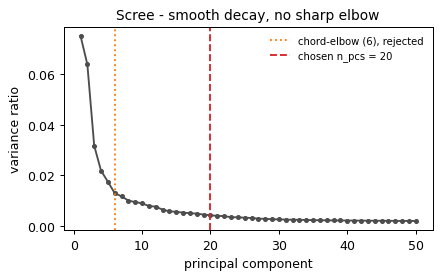

In [6]:
vr = m.uns['pca']['variance_ratio']
x = np.arange(1, len(vr)+1)
xn = (x-x.min())/(x.max()-x.min()); yn = (vr-vr.min())/(vr.max()-vr.min())
elbow = int(np.argmax((1-xn)-yn))+1
tail = vr[40:].mean(); noise_floor = int(np.argmax(vr < tail*1.1))+1
N_PCS = 20
print(f'chord-elbow      = {elbow}   (rejected: smooth scree biases this low)')
print(f'noise floor      ~ {noise_floor}')
print(f'chosen n_pcs     = {N_PCS}   (bounded: Kuerten 20 <= n_pcs <= Puram 40)')

fig, ax = plt.subplots(figsize=(5,3.2))
ax.plot(x, vr, '-o', ms=3, color='0.3')
ax.axvline(elbow, ls=':', color='tab:orange', label=f'chord-elbow ({elbow}), rejected')
ax.axvline(N_PCS, ls='--', color='tab:red', label=f'chosen n_pcs = {N_PCS}')
ax.set_xlabel('principal component'); ax.set_ylabel('variance ratio')
ax.set_title('Scree - smooth decay, no sharp elbow', size=11)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

### Harmony integration on `sample` + canonical embedding (n_pcs=20, θ=2)

In [7]:
THETA = 2
sce.pp.harmony_integrate(m, 'sample', theta=THETA, max_iter_harmony=20, random_state=SEED, verbose=False)
sc.pp.neighbors(m, n_neighbors=15, n_pcs=N_PCS, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(m, random_state=SEED, spread=1.0, min_dist=0.5)
sc.tl.leiden(m, resolution=0.5, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
print(f'embedding: {m.n_obs} cells, {m.obs.leiden.nunique()} Leiden clusters')

embedding: 3674 cells, 9 Leiden clusters


### Gate 1 — the decisive test: `n_pcs × theta` robustness sweep

Two per-neighborhood readouts against Harmony strength `theta`, faceted by `n_pcs`:
**mixing** = fraction of a cell's 30 nearest neighbors from a *different* patient (iLISI-style;
perfect-mixing ceiling `1 - sum(p_i^2)`), and **patient-pure fraction** = share of cells in Leiden
clusters dominated by one patient (>60% and >1.5x enrichment). If Gate 1 were an `n_pcs=6` artifact
(the attempt-1 hypothesis), raising `n_pcs` would restore mixing — it does not.

In [8]:
p = m.obs['sample'].value_counts(normalize=True)
ceiling = 1 - float((p.values**2).sum())
sv = m.obs['sample'].values
def mixing(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    return float((sv[idx] != sv[:,None]).mean())
def purity(mm, npcs):
    sc.pp.neighbors(mm, n_neighbors=15, n_pcs=npcs, use_rep='X_pca_harmony', random_state=SEED)
    sc.tl.leiden(mm, resolution=0.5, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
    ct = pd.crosstab(mm.obs.leiden, mm.obs['sample']); fr = ct.div(ct.sum(1),axis=0)
    dom = fr.max(1); ds = fr.idxmax(1); exc = np.array([dom[c]/p[ds[c]] for c in ct.index])
    pure = (dom>0.60)&(exc>1.5)
    return float(ct.sum(1)[pure.values].sum()/mm.n_obs)
rows=[]
for npcs in [6,15,20,30]:
    for th in [0,1,2,3]:
        mm = m.copy()
        if th==0: mm.obsm['X_pca_harmony']=mm.obsm['X_pca'].copy()
        else: sce.pp.harmony_integrate(mm,'sample',theta=th,max_iter_harmony=20,random_state=SEED,verbose=False)
        rows.append(dict(n_pcs=npcs, theta=th, mixing=mixing(mm.obsm['X_pca_harmony'][:,:npcs]),
                         frac_pure=purity(mm,npcs)))
sweep = pd.DataFrame(rows)
print(f'perfect-mixing ceiling = {ceiling:.2f}   (P11+P01 = {p.nlargest(2).sum():.0%} of cells)')
print(sweep.pivot(index='theta',columns='n_pcs',values='frac_pure').round(2).to_string())

perfect-mixing ceiling = 0.69   (P11+P01 = 72% of cells)
n_pcs    6     15    20    30
theta                        
0      1.00  1.00  1.00  1.00
1      0.73  0.88  0.90  0.90
2      0.56  0.51  0.50  0.56
3      0.01  0.02  0.09  0.09


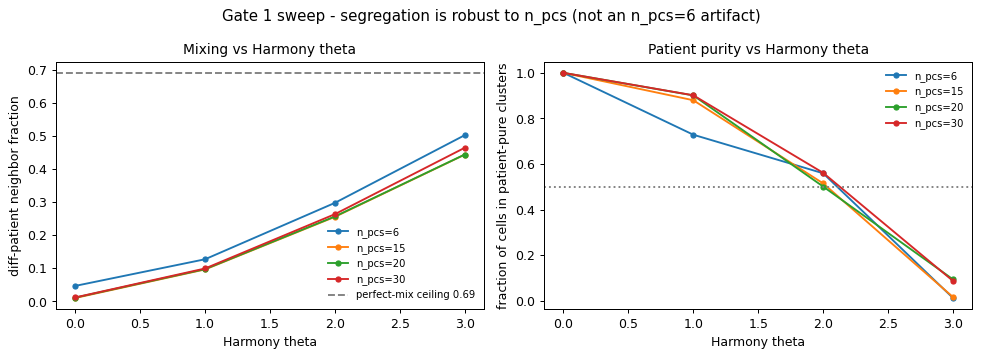

In [9]:
fig, axes = plt.subplots(1,2, figsize=(11,4))
for npcs, g in sweep.groupby('n_pcs'):
    axes[0].plot(g.theta, g.mixing, '-o', ms=4, label=f'n_pcs={npcs}')
    axes[1].plot(g.theta, g.frac_pure, '-o', ms=4, label=f'n_pcs={npcs}')
axes[0].axhline(ceiling, ls='--', color='0.5', label=f'perfect-mix ceiling {ceiling:.2f}')
axes[0].set_ylabel('diff-patient neighbor fraction'); axes[0].set_title('Mixing vs Harmony theta', size=11)
axes[1].axhline(0.5, ls=':', color='0.5'); axes[1].set_ylabel('fraction of cells in patient-pure clusters')
axes[1].set_title('Patient purity vs Harmony theta', size=11)
for a in axes: a.set_xlabel('Harmony theta'); a.legend(frameon=False, fontsize=8)
fig.suptitle('Gate 1 sweep - segregation is robust to n_pcs (not an n_pcs=6 artifact)', size=12)
fig.tight_layout(); plt.show()

### Biology before geometry — embedding + sub-region identity

Lead with the embedding itself, then settle each sub-region's biology (patient, cell cycle, 3CA
meta-program) **before** the gate call (evaluation lesson: biology before geometry).

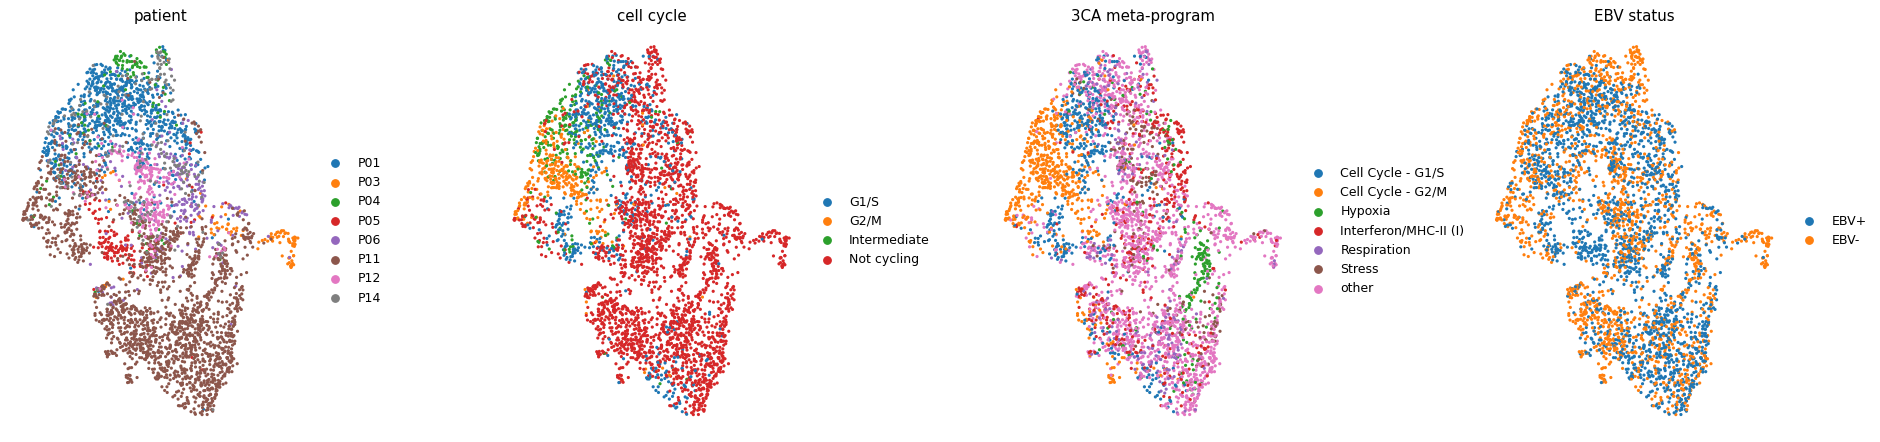

In [10]:
top = m.obs['mp_top'].value_counts().index[:6].tolist()
m.obs['_mp6'] = pd.Categorical([x if x in top else 'other' for x in m.obs['mp_top'].astype(str)])
fig, axes = plt.subplots(1,4, figsize=(21,5))
for ax,(col,ttl) in zip(axes,[('sample','patient'),('cell_cycle_phase','cell cycle'),
                               ('_mp6','3CA meta-program'),('ebv','EBV status')]):
    sc.pl.umap(m, color=col, ax=ax, show=False, size=26, frameon=False, title=ttl, legend_loc='right margin')
fig.tight_layout(); plt.show()

In [11]:
# continuity: connected components on a UMAP radius graph
X = m.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=2).fit(X).kneighbors(X)
r = 6*np.median(d[:,1]); A = NearestNeighbors(radius=r).fit(X).radius_neighbors_graph(X)
ncomp, lab = connected_components(csr_matrix(A), directed=False)
big = pd.Series(lab).value_counts().iloc[0]
print(f'continuity: {ncomp} component(s); largest = {big}/{m.n_obs} = {big/m.n_obs:.3f}')

ct = pd.crosstab(m.obs.leiden, m.obs['sample']); fr = ct.div(ct.sum(1),axis=0)
rows=[]
for cl in m.obs.leiden.cat.categories:
    sub = m.obs[m.obs.leiden==cl]
    rows.append(dict(leiden=cl, n=len(sub),
        mp_top=sub.mp_top.mode().iloc[0] if sub.mp_top.notna().any() else 'NA',
        cycling=round((sub.cell_cycle_phase!='Not cycling').mean(),2),
        dom_patient=fr.loc[cl].idxmax(), dom_frac=round(fr.loc[cl].max(),2),
        enrich=round(fr.loc[cl].max()/p[fr.loc[cl].idxmax()],1)))
tab = pd.DataFrame(rows)
pure = tab[(tab.dom_frac>0.60)&(tab.enrich>1.5)]
print(tab.to_string(index=False))
print(f'\npatient-pure: {len(pure)}/{len(tab)} clusters = {pure.n.sum()/m.n_obs:.0%} of cells;'
      f' of which non-cycling = {pure[pure.cycling<0.5].n.sum()} cells')

continuity: 1 component(s); largest = 3674/3674 = 1.000
leiden   n                 mp_top  cycling dom_patient  dom_frac  enrich
     0 554      Cell Cycle - G1/S     0.60         P01      0.71     3.1
     1 426  Interferon/MHC-II (I)     0.19         P01      0.32     1.4
     2 581      Cell Cycle - G2/M     0.86         P11      0.40     0.8
     3 181                 Stress     0.22         P12      0.56     8.8
     4 496     Protein maturation     0.19         P11      0.41     0.8
     5 116                Hypoxia     0.02         P11      0.79     1.6
     6 755 Translation initiation     0.21         P11      0.99     2.0
     7 415  Interferon/MHC-II (I)     0.03         P11      0.94     1.9
     8 150                 EpiSen     0.02         P03      0.57    19.5

patient-pure: 4/9 clusters = 50% of cells; of which non-cycling = 1286 cells


### Gate 1 decision — **NO-GO**

Checked against the spec (§2): Gate 1 passes only if the malignant structure is **both** sample-mixed
**and** continuous.

- **Continuous?** Yes — one connected component.
- **Mixed?** **No.** ~50% of cells sit in patient-pure Leiden clusters at θ=2 (≈90% at θ=1), and this
  holds across `n_pcs` in {15, 20, 30} — so it is **not** the attempt-1 `n_pcs=6` artifact. Raising
  `n_pcs` makes raw mixing *worse* (more PCs capture more patient-private CNV structure). Only θ=3
  erases the patient signal, which over-integrates. The purest clusters are **non-cycling P11** cells —
  patient-private identity, not a shared axis or a proliferation confound.

Gate 1 requires *both*; mixing fails → **Gate 1 = NO-GO** (binary; not a "Conditional GO"). No
trajectory is fit. Per §6 the deliverables are **01_preprocessing + 02_expression** (renumbered),
plus `summary.pdf` and one `analysis_log.csv` row.

### Save `processed.h5ad` and `samples.pdf`

saved processed.h5ad + samples.pdf


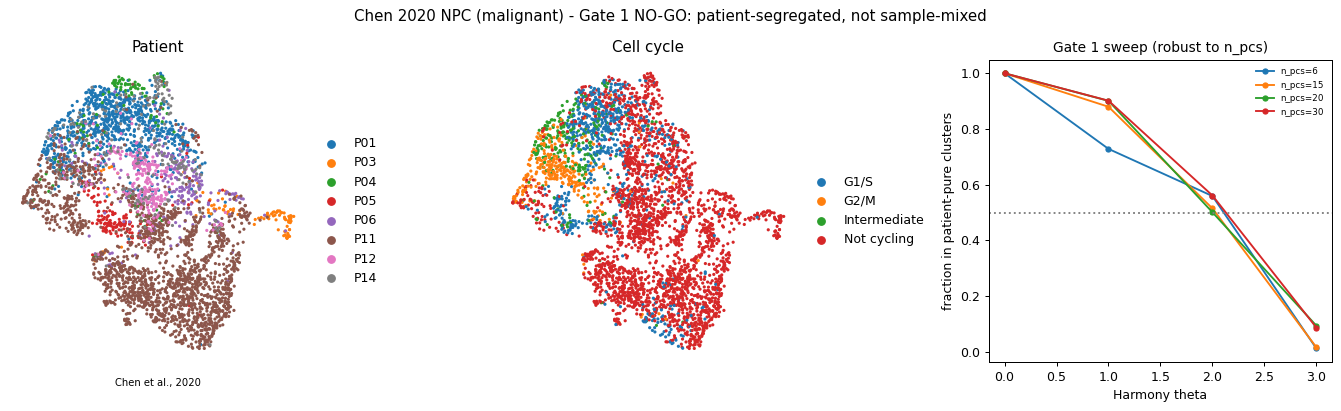

In [12]:
m.obs['n_pcs'] = N_PCS
m.write(os.path.join(pth_out, 'processed.h5ad'))

fig = plt.figure(figsize=(15,4.6))
gs = fig.add_gridspec(1,3, width_ratios=[1,1,1.15])
ax0 = fig.add_subplot(gs[0]); ax1 = fig.add_subplot(gs[1]); ax2 = fig.add_subplot(gs[2])
sc.pl.umap(m, color='sample', ax=ax0, show=False, size=26, frameon=False, title='Patient', legend_loc='right margin')
sc.pl.umap(m, color='cell_cycle_phase', ax=ax1, show=False, size=26, frameon=False, title='Cell cycle', legend_loc='right margin')
for npcs, g in sweep.groupby('n_pcs'):
    ax2.plot(g.theta, g.frac_pure, '-o', ms=4, label=f'n_pcs={npcs}')
ax2.axhline(0.5, ls=':', color='0.5')
ax2.set_xlabel('Harmony theta'); ax2.set_ylabel('fraction in patient-pure clusters')
ax2.set_title('Gate 1 sweep (robust to n_pcs)', size=11); ax2.legend(frameon=False, fontsize=7)
fig.suptitle('Chen 2020 NPC (malignant) - Gate 1 NO-GO: patient-segregated, not sample-mixed', size=12)
ax0.text(.5,-.08,'Chen et al., 2020', ha='center', transform=ax0.transAxes, size=8)
fig.tight_layout()
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved processed.h5ad + samples.pdf')